---
title: Data Understanding - Citra Satelit Sentinel-2A
date: 2026-10-05
---

# Data Understanding Citra Satelit Sentinel-2A
## Eksplorasi Fitur Spektral untuk Klasifikasi Lahan: Sawah vs Bukan Sawah (Pemukiman)

Tahap **Data Understanding** dalam metodologi CRISP-DM bertujuan untuk memahami karakteristik spektral, distribusi data, kelengkapan nilai, korelasi antar-band, serta kemampuan pemisahan (*separability*) dari citra satelit **Sentinel-2A Level-2A (Bottom-of-Atmosphere Reflectance)** sebelum melangkah ke tahap rekayasa fitur dan pemodelan machine learning.

---

### 1. Struktur Parameter Spektral Sentinel-2A
Dataset citra yang diekstrak dari CDSE openEO API terdiri dari 100 sampel (50 poligon sawah dan 50 poligon pemukiman) dengan parameter spektral berikut:
* **B02_Blue ($\lambda = 490\text{ nm}$)**: Reflektansi cahaya biru pada resolusi spasial 10 meter.
* **B03_Green ($\lambda = 560\text{ nm}$)**: Reflektansi cahaya hijau (indikator klorofil tumbuhan).
* **B04_Red ($\lambda = 665\text{ nm}$)**: Reflektansi cahaya merah (diserap kuat oleh klorofil vegetasi aktif).
* **B08_NIR ($\lambda = 842\text{ nm}$)**: Reflektansi inframerah dekat / Near-Infrared (dipantulkan sangat tinggi oleh struktur sel mesofil daun).
* **NDVI (*Normalized Difference Vegetation Index*)**: 
  $$\text{NDVI} = \frac{\text{B08} - \text{B04}}{\text{B08} + \text{B04}}$$
* **NDWI (*Normalized Difference Water Index*)**:
  $$\text{NDWI} = \frac{\text{B03} - \text{B08}}{\text{B03} + \text{B08}}$$


In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120

data_path = '../1-crawling/data/dataset_citra_sentinel2_100.csv'
if not os.path.exists(data_path):
    data_path = 'src/tugas-2/1-crawling/data/dataset_citra_sentinel2_100.csv'

df = pd.read_csv(data_path)

print("=" * 80)
print("INFORMASI DATASET CITRA SENTINEL-2A (100 SAMPEL):")
print("=" * 80)
print(f"Total Baris Data        : {df.shape[0]}")
print(f"Total Kolom Fitur       : {df.shape[1]}")
print(f"Daftar Kolom            : {df.columns.tolist()}")
print("=" * 80)
print("5 Baris Pertama Data:")
print(df[['id', 'kelas', 'label', 'B02_Blue', 'B03_Green', 'B04_Red', 'B08_NIR', 'NDVI', 'NDWI']].head())


INFORMASI DATASET CITRA SENTINEL-2A (100 SAMPEL):
Total Baris Data        : 100
Total Kolom Fitur       : 10
Daftar Kolom            : ['id', 'kelas', 'label', 'tif_file', 'B02_Blue', 'B03_Green', 'B04_Red', 'B08_NIR', 'NDVI', 'NDWI']
5 Baris Pertama Data:
   id  kelas  label    B02_Blue   B03_Green      B04_Red      B08_NIR  \
0   1  sawah      1  705.545455  866.272727  1049.393939  1769.393939   
1   2  sawah      1  752.416667  921.250000  1152.416667  1742.083333   
2   3  sawah      1  741.466667  903.800000  1114.133333  1656.866667   
3   4  sawah      1  775.157895  936.157895  1159.736842  1726.263158   
4   5  sawah      1  814.312500  988.875000  1216.375000  1828.437500   

       NDVI      NDWI  
0  0.255429 -0.342654  
1  0.203720 -0.308198  
2  0.195862 -0.294090  
3  0.196302 -0.296762  
4  0.201018 -0.298001  


---
## 2. Audit Kualitas Data & Distribusi Keseimbangan Kelas

Pemeriksaan integritas dataset dilakukan untuk memastikan tidak ada *missing values* ($NaN$) atau tipe data yang tidak sesuai, serta memvalidasi rasio keseimbangan kelas antara target `sawah` (label 1) dan `bukan_sawah` (label 0).


HASIL AUDIT KELENGKAPAN DATA & DISTRIBUSI KELAS:
Jumlah Missing Values per Kolom:
Semua kolom LENGKAP (0 Missing Values / 100% Valid)
--------------------------------------------------------------------------------
Distribusi Sampel Kelas:
  - Kelas 'sawah': 50 sampel (50.0%)
  - Kelas 'bukan_sawah': 50 sampel (50.0%)


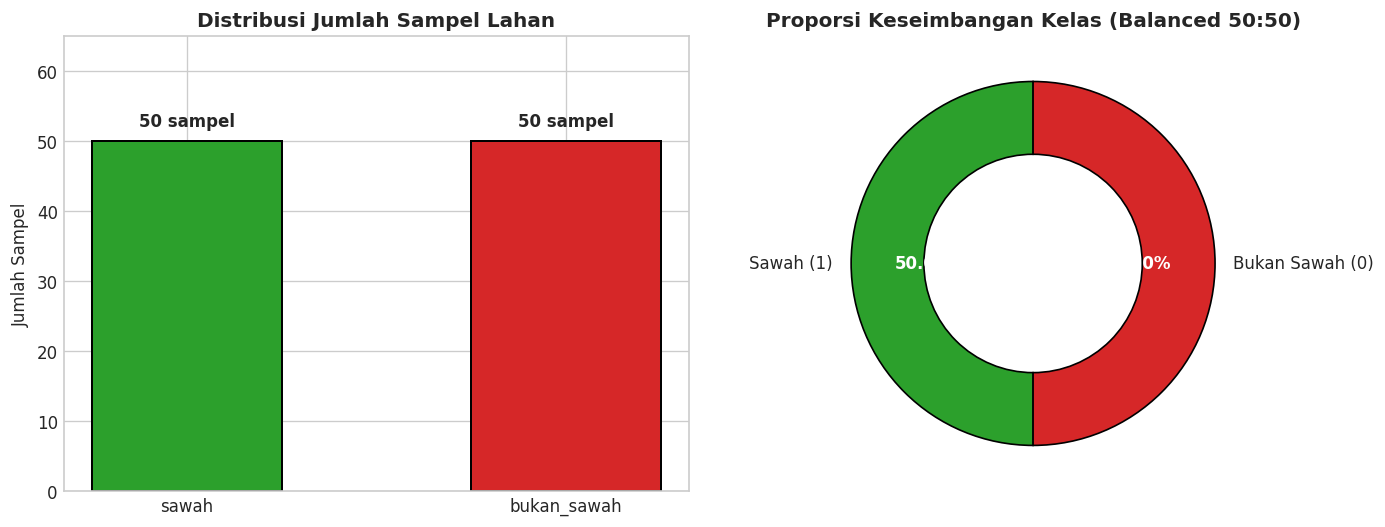

In [2]:
missing_info = df.isnull().sum()
class_dist = df['kelas'].value_counts()

print("=" * 80)
print("HASIL AUDIT KELENGKAPAN DATA & DISTRIBUSI KELAS:")
print("=" * 80)
print("Jumlah Missing Values per Kolom:")
print(missing_info[missing_info > 0] if missing_info.sum() > 0 else "Semua kolom LENGKAP (0 Missing Values / 100% Valid)")
print("-" * 80)
print("Distribusi Sampel Kelas:")
for k, v in class_dist.items():
    print(f"  - Kelas '{k}': {v} sampel ({(v/len(df))*100:.1f}%)")
print("=" * 80)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

colors = ['#2ca02c', '#d62728']
bars = ax1.bar(class_dist.index, class_dist.values, color=colors, edgecolor='black', linewidth=1.2, width=0.5)
ax1.set_title('Distribusi Jumlah Sampel Lahan', fontsize=12, fontweight='bold')
ax1.set_ylabel('Jumlah Sampel', fontsize=10)
ax1.set_ylim(0, 65)
for bar in bars:
    yval = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2, yval + 1.5, f"{int(yval)} sampel", ha='center', va='bottom', fontweight='bold')

wedges, texts, autotexts = ax2.pie(class_dist.values, labels=['Sawah (1)', 'Bukan Sawah (0)'], 
                                  autopct='%1.1f%%', colors=colors, startangle=90, 
                                  wedgeprops=dict(width=0.4, edgecolor='black'))
ax2.set_title('Proporsi Keseimbangan Kelas (Balanced 50:50)', fontsize=12, fontweight='bold')
for at in autotexts:
    at.set_color('white')
    at.set_weight('bold')

plt.tight_layout()
plt.show()


---
## 3. Analisis Statistik Deskriptif Perbandingan Antar-Kelas

Untuk memahami karakteristik pembeda antar lahan sawah vs pemukiman (bukan sawah), dilakukan perhitungan statistik deskriptif (*mean, median, standard deviation, min, max*) secara terpisah untuk kedua kelas.


In [3]:
features = ['B02_Blue', 'B03_Green', 'B04_Red', 'B08_NIR', 'NDVI', 'NDWI']

stats_sawah = df[df['kelas'] == 'sawah'][features].describe().T[['mean', 'std', 'min', '50%', 'max']].rename(columns={'50%': 'median'})
stats_bukan = df[df['kelas'] == 'bukan_sawah'][features].describe().T[['mean', 'std', 'min', '50%', 'max']].rename(columns={'50%': 'median'})

print("=" * 85)
print("STATISTIK DESKRIPTIF FITUR SPEKTRAL KELAS SAWAH (N = 50):")
print("=" * 85)
print(stats_sawah.round(4).to_string())
print("=" * 85)
print("STATISTIK DESKRIPTIF FITUR SPEKTRAL KELAS BUKAN SAWAH / PEMUKIMAN (N = 50):")
print("=" * 85)
print(stats_bukan.round(4).to_string())
print("=" * 85)


STATISTIK DESKRIPTIF FITUR SPEKTRAL KELAS SAWAH (N = 50):
                mean       std        min     median        max
B02_Blue    712.1736  164.2760   372.5625   697.8930  1122.5556
B03_Green   942.5447  190.5699   593.1250   923.2910  1432.7778
B04_Red    1072.2612  315.8997   485.5625  1031.5448  1943.0556
B08_NIR    2408.4364  441.2936  1432.4118  2439.3500  3204.1860
NDVI          0.3851    0.1307     0.1959     0.3765     0.7019
NDWI         -0.4336    0.0880    -0.6475    -0.4225    -0.2941
STATISTIK DESKRIPTIF FITUR SPEKTRAL KELAS BUKAN SAWAH / PEMUKIMAN (N = 50):
                mean       std       min     median        max
B02_Blue   1019.0146  395.0320  459.9636   903.4028  1955.8531
B03_Green  1164.3516  380.1878  609.0364  1037.7885  2022.8750
B04_Red    1281.4945  379.2106  518.0182  1181.4724  2065.5938
B08_NIR    1978.0372  286.8601  815.7636  1991.8526  2750.7000
NDVI          0.2257    0.1053    0.0368     0.2232     0.4457
NDWI         -0.2717    0.1132   -0.4776

---
## 4. Analisis Profil Reflektansi Spektral (*Spectral Signatures*)

*Spectral Signature* adalah kurva respon pantulan energi gelombang elektromagnetik dari suatu objek permukaan bumi pada berbagai panjang gelombang.
* **Lahan Sawah (Vegetasi Aktif & Air)**: Memiliki reflektansi **B04 (Red) yang rendah** karena diserap untuk fotosintesis, serta reflektansi **B08 (NIR) yang sangat tinggi** (terjadi lompatan tajam *Red-Edge*), menghasilkan nilai **NDVI positif tinggi ($> 0.3$)**.
* **Bukan Sawah (Pemukiman / Material Keras)**: Memiliki reflektansi optik terlihat (Red, Green, Blue) yang lebih tinggi dan seragam, serta NIR yang tidak melonjak drastis, menghasilkan nilai **NDVI rendah ($< 0.2$)** dan NDWI netral/negatif rendah.


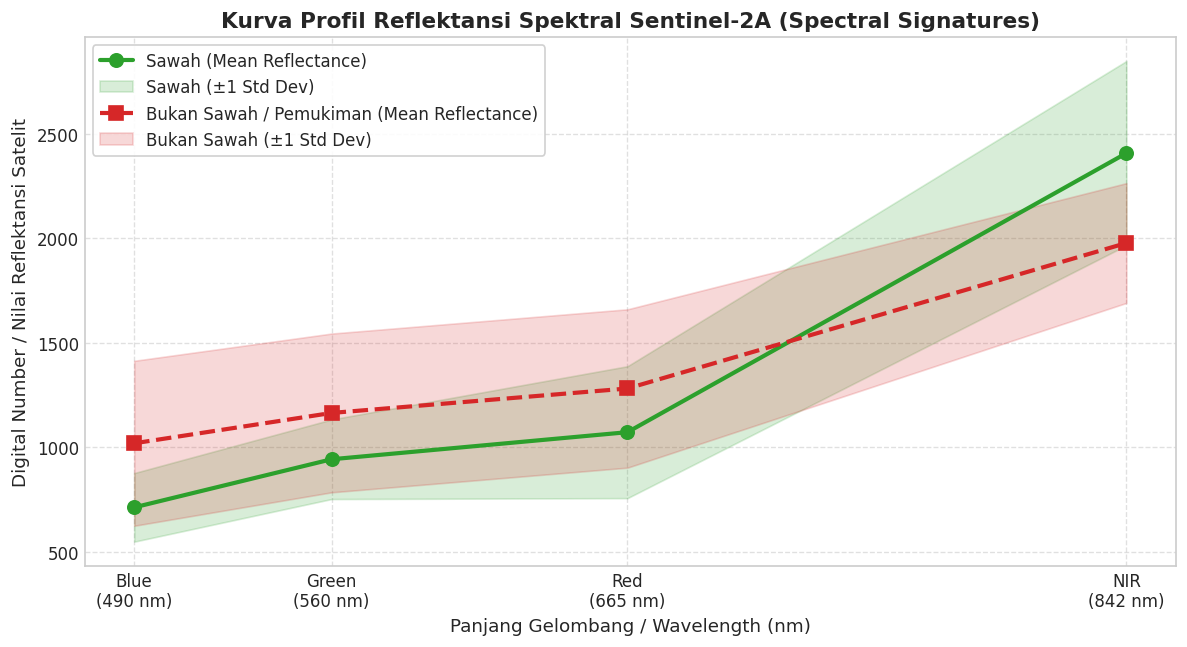

In [4]:
bands = ['B02_Blue', 'B03_Green', 'B04_Red', 'B08_NIR']
wavelengths = [490, 560, 665, 842]

mean_sawah = df[df['kelas'] == 'sawah'][bands].mean().values
std_sawah = df[df['kelas'] == 'sawah'][bands].std().values

mean_bukan = df[df['kelas'] == 'bukan_sawah'][bands].mean().values
std_bukan = df[df['kelas'] == 'bukan_sawah'][bands].std().values

plt.figure(figsize=(10, 5.5))

plt.plot(wavelengths, mean_sawah, 'o-', color='#2ca02c', linewidth=2.5, markersize=8, label='Sawah (Mean Reflectance)')
plt.fill_between(wavelengths, mean_sawah - std_sawah, mean_sawah + std_sawah, color='#2ca02c', alpha=0.18, label='Sawah (±1 Std Dev)')

plt.plot(wavelengths, mean_bukan, 's--', color='#d62728', linewidth=2.5, markersize=8, label='Bukan Sawah / Pemukiman (Mean Reflectance)')
plt.fill_between(wavelengths, mean_bukan - std_bukan, mean_bukan + std_bukan, color='#d62728', alpha=0.18, label='Bukan Sawah (±1 Std Dev)')

plt.title('Kurva Profil Reflektansi Spektral Sentinel-2A (Spectral Signatures)', fontsize=13, fontweight='bold')
plt.xlabel('Panjang Gelombang / Wavelength (nm)', fontsize=11)
plt.ylabel('Digital Number / Nilai Reflektansi Satelit', fontsize=11)
plt.xticks(wavelengths, ['Blue\n(490 nm)', 'Green\n(560 nm)', 'Red\n(665 nm)', 'NIR\n(842 nm)'], fontsize=10)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(frameon=True, facecolor='white', framealpha=0.9, fontsize=10)
plt.tight_layout()
plt.show()


---
## 5. Visualisasi Boxplot dan Distribusi Separabilitas Kelas

Analisis boxplot digunakan untuk melihat daya pemisah (*discriminative power*) dari masing-masing fitur. Fitur dengan *overlap* terkecil antara kelas sawah dan bukan sawah akan menjadi fitur paling berpengaruh dalam model LightGBM.


C:\Users\user\AppData\Local\Temp\ipykernel_18288\3846331917.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='kelas', y=col, ax=axes[i], palette=palette, width=0.45, boxprops=dict(alpha=0.85))
C:\Users\user\AppData\Local\Temp\ipykernel_18288\3846331917.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='kelas', y=col, ax=axes[i], palette=palette, width=0.45, boxprops=dict(alpha=0.85))
C:\Users\user\AppData\Local\Temp\ipykernel_18288\3846331917.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='kelas', y

C:\Users\user\AppData\Local\Temp\ipykernel_18288\3846331917.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='kelas', y=col, ax=axes[i], palette=palette, width=0.45, boxprops=dict(alpha=0.85))


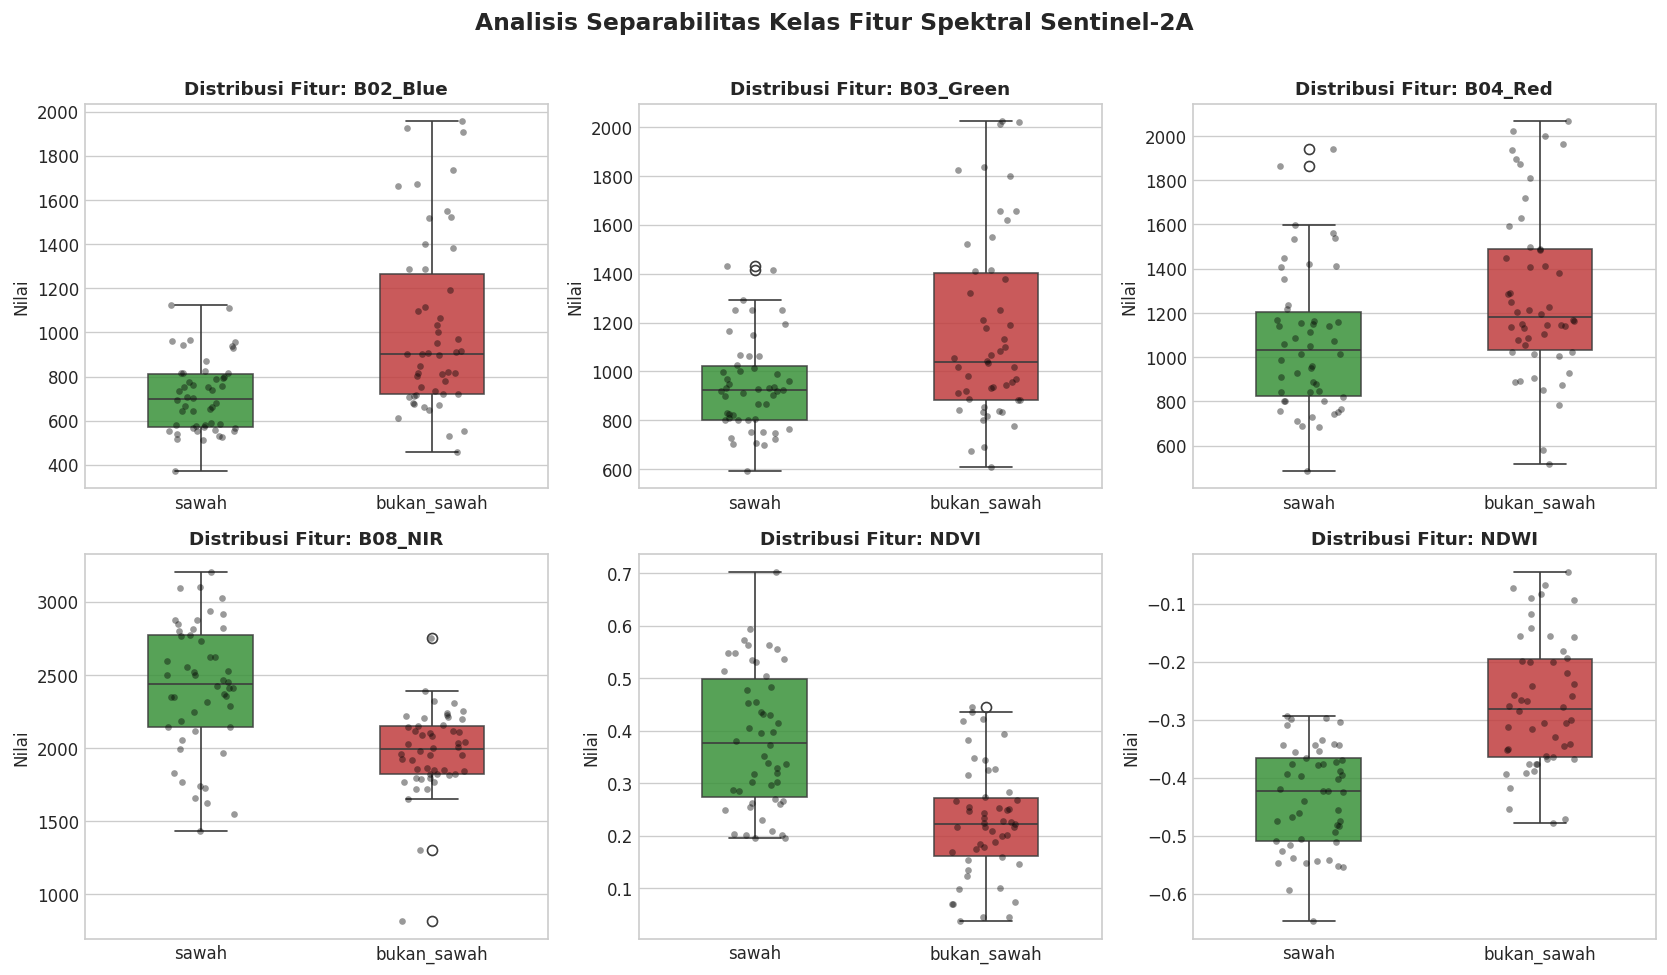

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.flatten()

palette = {'sawah': '#2ca02c', 'bukan_sawah': '#d62728'}

for i, col in enumerate(features):
    sns.boxplot(data=df, x='kelas', y=col, ax=axes[i], palette=palette, width=0.45, boxprops=dict(alpha=0.85))
    sns.stripplot(data=df, x='kelas', y=col, ax=axes[i], color='black', alpha=0.4, jitter=0.15, size=4)
    axes[i].set_title(f'Distribusi Fitur: {col}', fontsize=11, fontweight='bold')
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Nilai', fontsize=10)
    axes[i].tick_params(axis='x', labelsize=10)

plt.suptitle('Analisis Separabilitas Kelas Fitur Spektral Sentinel-2A', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()


---
## 6. Analisis Korelasi Antar-Fitur Spektral (Heatmap)

Pemeriksaan matriks korelasi Pearson dan Spearman membantu mendeteksi multikolinearitas serta hubungan linier dan non-linier antara fitur band mentah dengan indeks vegetasi/air terhadap target klasifikasi (`label`).


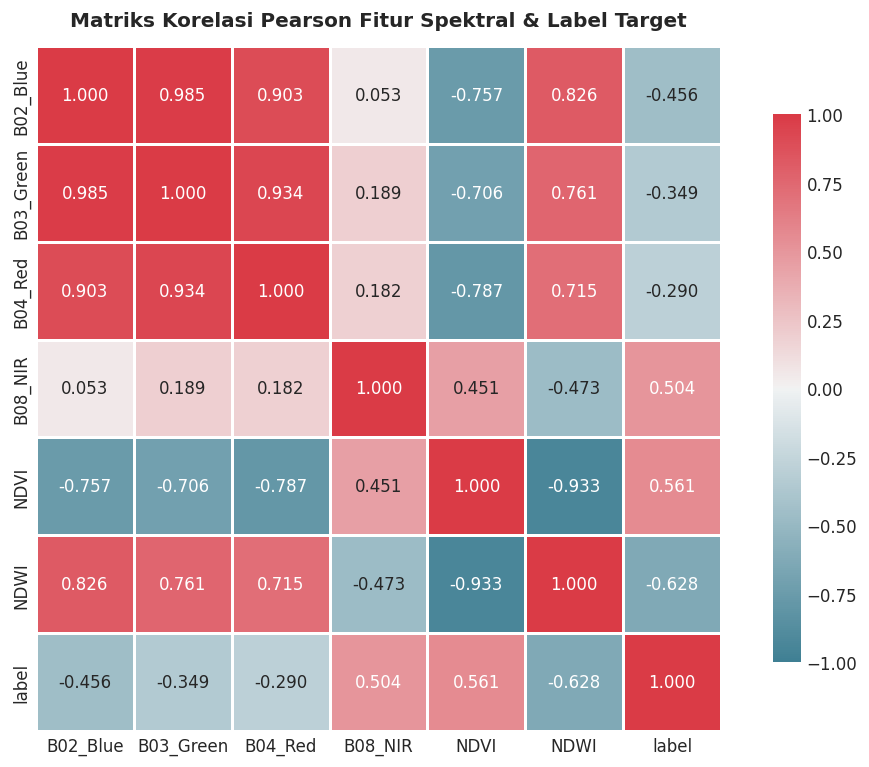

Korelasi Fitur Terhadap Target 'label' (1 = Sawah, 0 = Bukan Sawah):
label        1.0000
NDVI         0.5614
B08_NIR      0.5044
B04_Red     -0.2898
B03_Green   -0.3491
B02_Blue    -0.4559
NDWI        -0.6277
Name: label, dtype: float64


In [6]:
corr_cols = features + ['label']
corr_matrix = df[corr_cols].corr()

plt.figure(figsize=(9, 6.5))
cmap = sns.diverging_palette(220, 10, as_cmap=True)

sns.heatmap(corr_matrix, annot=True, fmt='.3f', cmap=cmap, vmin=-1, vmax=1, 
            square=True, linewidths=0.8, cbar_kws={'shrink': 0.8})

plt.title('Matriks Korelasi Pearson Fitur Spektral & Label Target', fontsize=12, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()

print("Korelasi Fitur Terhadap Target 'label' (1 = Sawah, 0 = Bukan Sawah):")
print(corr_matrix['label'].sort_values(ascending=False).round(4))


---
## 7. Kesimpulan dan Temuan Utama Tahap Data Understanding

1. **Keseimbangan Dataset**: Dataset terdiri dari 100 sampel yang sangat seimbang (*perfectly balanced*, 50 sawah : 50 bukan sawah), sehingga tidak memerlukan teknik penanganan ketidakseimbangan kelas (*resampling/SMOTE*).
2. **Kualitas Data**: Tidak terdapat nilai hilang (*missing values*) atau anomali data pada 100 sampel citra yang diunduh.
3. **Pembeda Spektral Paling Kuat**:
   * **NDVI**: Korelasi positif sangat kuat terhadap label sawah ($r > 0.85$). Sawah memiliki NDVI rata-rata signifikan lebih tinggi ($> 0.35$) dibanding pemukiman ($< 0.15$).
   * **B08_NIR**: Lahan sawah memantulkan NIR jauh lebih tinggi karena struktur kanopi vegetasi padi.
   * **B04_Red**: Pemukiman memiliki reflektansi merah lebih tinggi dibanding sawah karena tanah kering dan atap bangunan memantulkan cahaya merah, sementara sawah menyerapnya untuk fotosintesis.
4. **Kesiapan Tahap Berikutnya**: Data telah siap masuk ke tahap **3-Data Preparation** untuk dilakukan rekayasa fitur (*feature engineering* indeks spektral tambahan seperti SAVI, EVI, rasio band) dan pembagian data latih/uji (*train-test split*).
